In [3]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
conn = sqlite3.connect(r"..\power bi\earthquakes_API.db") # Connexión a .db
cursor = conn.cursor()

In [26]:
def run_query(query):
    return pd.read_sql_query(query, conn)

In [4]:
query = """
select is_ocean , count(*) as total 
from earthquakes_clean 
where is_ocean is not null 
group by is_ocean 
order by total desc;
"""

In [ ]:
df = run_query(query)
df.to_csv(r"..\power bi\terremoto_zona.csv")
print(df)

  is_ocean    total
0        0  2445684
1        1   644285


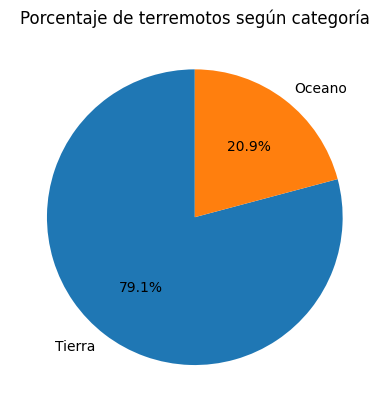

In [6]:
df["zona"] = df["is_ocean"].astype(int).map({1:"Oceano", 0:"Tierra"})
plt.pie(
    df["total"],
    labels=df["zona"],
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Porcentaje de terremotos según categoría")
plt.show()

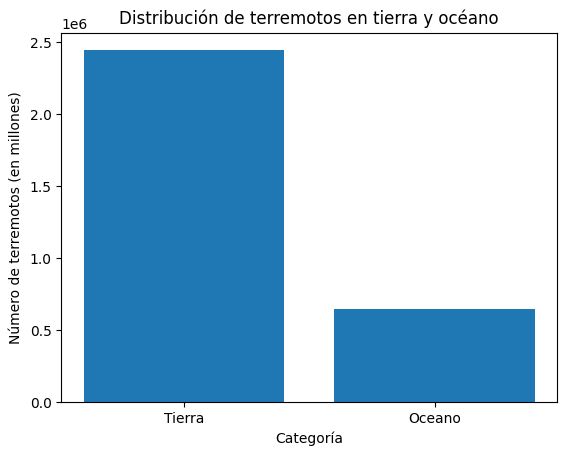

In [7]:
plt.figure()
df["zona"] = df["is_ocean"].astype(int).map({1:"Oceano", 0:"Tierra"}) # Convierte 1/0 en Oceano y Tierra
plt.bar(df["zona"], df["total"]) # Define cada columna
plt.title("Distribución de terremotos en tierra y océano")
plt.xlabel("Categoría")
plt.ylabel("Número de terremotos (en millones)")

plt.show()

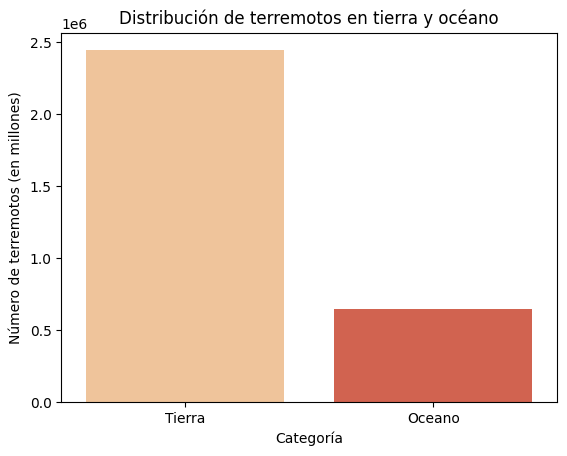

<Figure size 640x480 with 0 Axes>

In [8]:
df["zona"] = df["is_ocean"].astype(int).map({1:"Oceano", 0:"Tierra"})

plt.figure()

sns.barplot(
    x='zona',
    y='total',
    data=df,
    hue='zona',
    palette="OrRd",
    legend=False
)

plt.title("Distribución de terremotos en tierra y océano")
plt.xlabel("Categoría")
plt.ylabel("Número de terremotos (en millones)")

plt.show()
plt.savefig("../images/magnitudes.png", dpi=300, bbox_inches="tight")

In [31]:
query = """
select geo_country, count(*) as total
from earthquakes_clean
where geo_country is not null
and geo_country is not "Ocean"
group by geo_country
order by total desc
;
"""

In [ ]:
df = run_query(query)
df.to_csv(r"..\power bi\terremoto_quantity_by_country_full.csv")
print(df)

                  geo_country    total
0    United States of America  2230953
1                      Mexico    31211
2                      Canada    25165
3                 Puerto Rico    16537
4                       Chile    15546
..                        ...      ...
168                   Curaçao        1
169                  Cameroon        1
170                     Benin        1
171                  Barbados        1
172                  Anguilla        1

[173 rows x 2 columns]


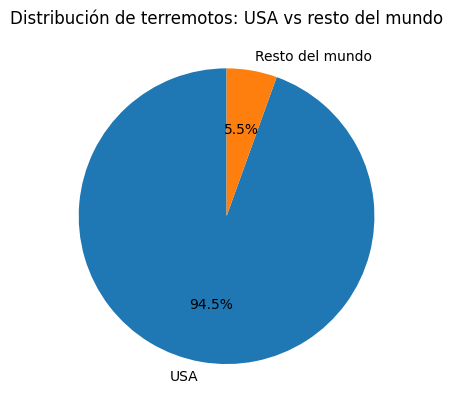

In [11]:
usa_total = df[df["geo_country"] == "United States of America"]["total"].values[0]
rest_total = df[df["geo_country"] != "United States of America"]["total"].sum()

df_usa = pd.DataFrame({
    "category": ["USA", "Resto del mundo"],
    "total": [usa_total, rest_total]
})

plt.figure()

plt.pie(
    df_usa["total"],
    labels=df_usa["category"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribución de terremotos: USA vs resto del mundo")

plt.show()

In [22]:
query = """
select geo_country, count(*) as total
from earthquakes_clean
where geo_country is not null
and mag > 4
and geo_country is not "Ocean"
group by geo_country
order by total desc
;
"""

In [ ]:
df = run_query(query)
df.to_csv(r"..\power bi\terremoto_country_4.csv")
print(df)

          geo_country  total
0           Indonesia   7889
1               Chile   6493
2               China   6269
3    Papua New Guinea   5266
4           Argentina   4319
..                ...    ...
150             Congo      1
151          Cameroon      1
152             Benin      1
153           Belgium      1
154          Barbados      1

[155 rows x 2 columns]


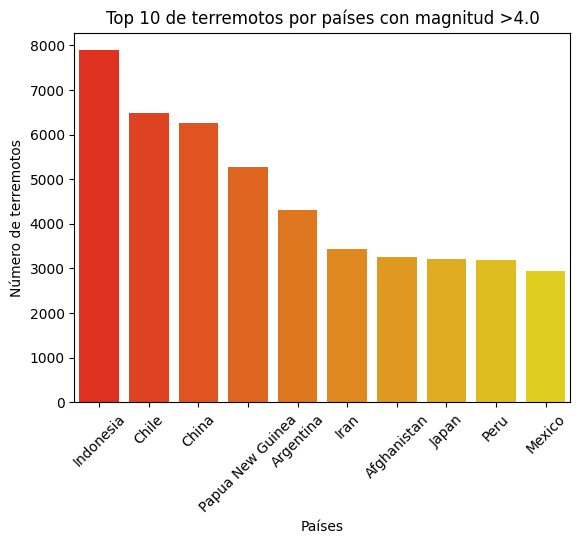

In [14]:
plt.figure()

sns.barplot(
    x='geo_country',
    y='total',
    data=df,
    hue='geo_country',
    palette="autumn",
    legend=False,
    

)

plt.title("Top 10 de terremotos por países con magnitud >4.0")
plt.xlabel("Países")
plt.ylabel("Número de terremotos")
plt.xticks(rotation=45)

plt.show()

In [15]:
query = """
select year, count(*) as total
from earthquakes_clean
group by year
order by year;
"""

In [ ]:
df = run_query(query)
df.to_csv(r"..\power bi\terremoto_top_year.csv")
print(df)

    year   total
0   2000   69238
1   2001   70458
2   2002   89756
3   2003   96252
4   2004  110238
5   2005   99620
6   2006   98206
7   2007   93265
8   2008  120550
9   2009   85617
10  2010  119234
11  2011  102950
12  2012  101031
13  2013  108540
14  2014  129563
15  2015  119397
16  2016  118377
17  2017  127006
18  2018  175479
19  2019  171861
20  2020  187633
21  2021  153550
22  2022  139971
23  2023  138805
24  2024  137055
25  2025  126317


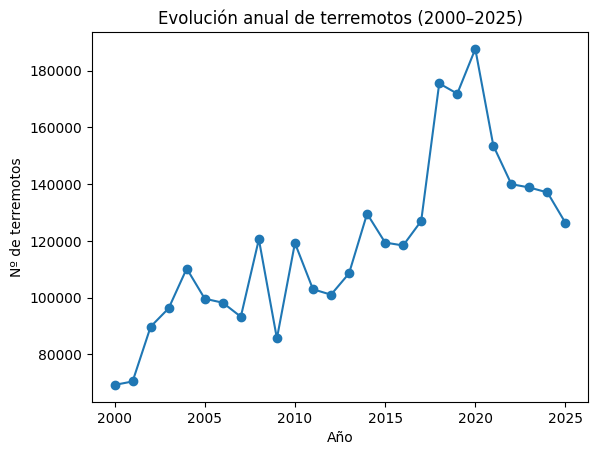

In [17]:
plt.plot(df['year'],df['total'],marker="o") # X:year Y:total
plt.title("Evolución anual de terremotos (2000–2025)")
plt.xlabel("Año")
plt.ylabel("Nº de terremotos")
plt.show()

In [18]:
query = """
select 
    CASE 
        WHEN mag < 2 THEN 'Micro'
        WHEN mag >= 2 and mag < 4 THEN 'Menor'
        WHEN mag >= 4 and mag < 6 THEN 'Moderado'
        ELSE 'Fuerte'
    END AS Category,
    count(*) as N_earthquakes
from earthquakes_clean
group by Category
order by mag;
"""

In [ ]:
df = run_query(query)
df.to_csv(r"..\power bi\terremoto_category.csv")
print(df)

   Category  N_earthquakes
0     Micro        2123649
1     Menor         619539
2  Moderado         343040
3    Fuerte           3741


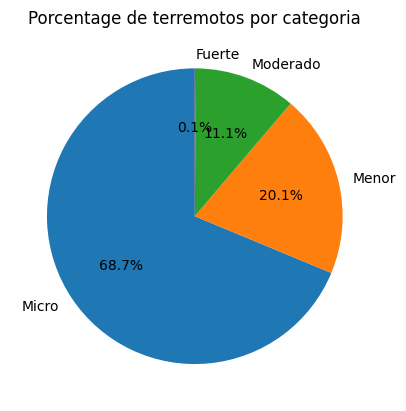

In [20]:
plt.pie(
    df["N_earthquakes"],
    labels=df["Category"],
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Porcentage de terremotos por categoria")
plt.show()

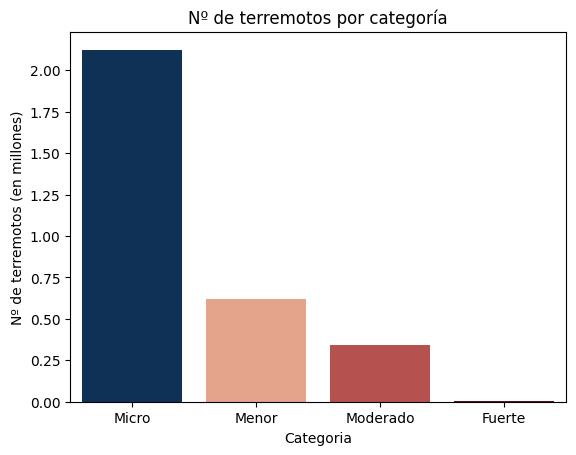

In [21]:
plt.figure()
df["millones"] = df["N_earthquakes"] / 1e6 # Evita que salga el 1e6 y mejora la lectura
sns.barplot(x=df["Category"],
            y=df["millones"],
            data=df,
            hue=df["millones"],
            palette="RdBu",
            legend=False)
plt.title("Nº de terremotos por categoría")
plt.xlabel("Categoria")
plt.ylabel("Nº de terremotos (en millones)")
#plt.ticklabel_format(style='',axis='y') 
plt.show()

In [22]:
query = """
select 
    case 
        when country = geo_country then 'equal'
        else 'not equal'
    end as Validation,
    count(*) as Total
from earthquakes_clean
group by Validation;
"""

In [23]:
df = run_query(query)
print(df)

  Validation    Total
0      equal   145917
1  not equal  2944052


In [ ]:
query = """
select geo_country, mag, year, month, day
from earthquakes_clean
where geo_country is not 'Ocean'
order by mag desc
limit 10
"""

In [ ]:
df = run_query(query)
df.to_csv(r"..\power bi\terremoto_top_by_country.csv")
print(df)

                geo_country  mag  year  month  day
0                 Indonesia  8.6  2005      3   28
1                      Peru  8.0  2019      5   26
2  United States of America  7.9  2002     11    3
3                     China  7.9  2008      5   12
4          Papua New Guinea  7.9  2017      1   22
5          Papua New Guinea  7.8  2000     11   17
6                     China  7.8  2001     11   14
7                     Chile  7.8  2005      6   13
8                    Canada  7.8  2012     10   28
9                     Nepal  7.8  2015      4   25


In [35]:
query = """
select year, geo_country, max(mag) as max_mag
from earthquakes_clean
where geo_country is not 'Ocean'
group by year, geo_country

"""

In [36]:
df = run_query(query)
df.to_csv(r"..\power bi\terremoto_top_by_country.csv")
print(df)

      year        geo_country  max_mag
0     2000        Afghanistan      6.3
1     2000            Albania      4.5
2     2000            Algeria      5.7
3     2000            Andorra      2.5
4     2000  Antigua and Barb.      3.5
...    ...                ...      ...
2689  2025         Uzbekistan      4.6
2690  2025            Vanuatu      5.9
2691  2025          Venezuela      6.3
2692  2025            Vietnam      4.7
2693  2025           Zimbabwe      4.3

[2694 rows x 3 columns]


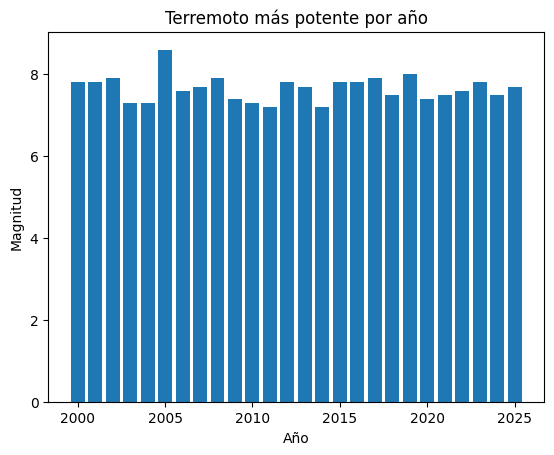

In [28]:
plt.figure()
plt.bar(df["year"],df["max_mag"])
plt.title("Terremoto más potente por año")
plt.xlabel("Año")
plt.ylabel("Magnitud")
plt.show()

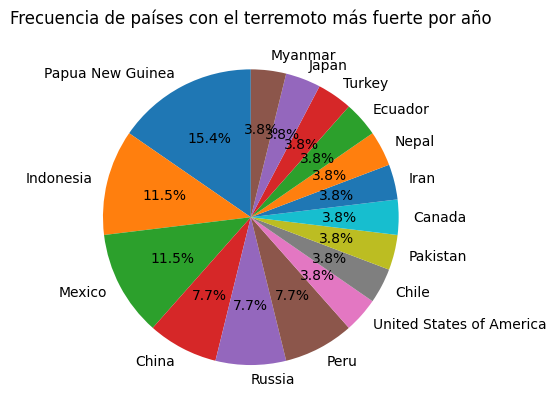

In [29]:
plt.figure()
df_counts = df["geo_country"].value_counts().reset_index()
df_counts.columns = ["geo_country", "count"]
plt.pie(
    df_counts['count'],
    labels=df_counts["geo_country"],
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Frecuencia de países con el terremoto más fuerte por año")
plt.show()

In [36]:
query = """
SELECT geo_country, year, month, mag
FROM (
    SELECT 
        geo_country,
        year,
        month,
        mag,
        ROW_NUMBER() OVER (
            PARTITION BY geo_country 
            ORDER BY mag DESC
        ) AS rn
    FROM earthquakes_clean
) t
WHERE rn <= 10
ORDER BY geo_country, mag DESC;
"""

In [ ]:
df = run_query(query)
df.to_csv(r"..\power bi\terremoto_top10_serial_by_country.csv")
print(df)

      geo_country  year  month  mag
0     Afghanistan  2015     10  7.5
1     Afghanistan  2002      3  7.4
2     Afghanistan  2004      4  6.6
3     Afghanistan  2009      1  6.6
4     Afghanistan  2016      4  6.6
...           ...   ...    ...  ...
1468     Zimbabwe  2024     12  4.6
1469     Zimbabwe  2006      5  4.5
1470     Zimbabwe  2019     11  4.5
1471     Zimbabwe  2021      8  4.3
1472     Zimbabwe  2025      1  4.3

[1473 rows x 4 columns]


In [8]:
query = """
select geo_country, year, count(*)
from earthquakes_clean
group by year, geo_country
"""

In [ ]:
df = run_query(query)
df.to_csv(r"..\power bi\terremoto_quantity_by_year_country.csv")
print(df)

            geo_country  year  count(*)
0           Afghanistan  2000       146
1               Albania  2000        47
2               Algeria  2000        30
3               Andorra  2000         2
4     Antigua and Barb.  2000         5
...                 ...   ...       ...
2715         Uzbekistan  2025         6
2716            Vanuatu  2025        15
2717          Venezuela  2025        22
2718            Vietnam  2025         8
2719           Zimbabwe  2025         1

[2720 rows x 3 columns]


In [33]:
query = """
select geo_country, year,
    CASE 
        WHEN mag < 2 THEN 'Micro'
        WHEN mag >= 2 and mag < 4 THEN 'Menor'
        WHEN mag >= 4 and mag < 6 THEN 'Moderado'
        ELSE 'Fuerte'
    END AS Category,
    count(*) as N_earthquakes
from earthquakes_clean
group by geo_country, year, Category
order by mag;
"""

In [34]:
df = run_query(query)
df.to_csv(r"..\power bi\terremoto_category_by_country.csv")
print(df)

           geo_country  year Category  N_earthquakes
0          Afghanistan  2003    Micro             41
1          Afghanistan  2004    Micro             32
2          Afghanistan  2005    Micro              4
3          Afghanistan  2006    Micro              5
4          Afghanistan  2007    Micro             19
...                ...   ...      ...            ...
4872              Iran  2013   Fuerte              3
4873            Canada  2012   Fuerte              1
4874             Chile  2005   Fuerte              1
4875             China  2001   Fuerte              1
4876  Papua New Guinea  2017   Fuerte              3

[4877 rows x 4 columns]
